# Assignment 1 — EDA & Baseline
## Pokémon TCG AI Battle Challenge (GROUP05 / CENG313)

**Group:** 05  
**Team name on Kaggle:** Attention Is All You Mew  
**Competition:** [The Pokémon Company — PTCG AI Battle Challenge Playground](https://www.kaggle.com/competitions/the-pokemon-company-ptcg-ai-battle-challenge-playground)  
**Repository:** `GROUP05_CENG313`

This notebook is the Assignment 1 deliverable. It describes the competition
problem, explores the replay data we collected, justifies the preprocessing
decisions, and evaluates two baselines: a tabular match-outcome model and the
rule-based agent that is actually submitted to Kaggle.

The notebook is written to be read on GitHub with its outputs saved. Data and
replays are **not committed**; see the README for the download commands.

## 1. Problem definition

### Task
The competition is a **simulation** competition, not a tabular Kaggle
competition. Every submission is an *agent*: the simulator sends an
observation containing the board state and a list of legal options, and the
agent returns the indices of the options it wants to play. Matches are played
in **best-of-three (BO3)** format.

### Target variable
There is no `train.csv` and no row-level target supplied by Kaggle. The
observed labels come from historical episodes: for every match we know which
player won (`reward = +1` for the winner, `-1` for the loser). For the
tabular baseline we therefore define the target as

$$y = \begin{cases}1 & \text{the player in this row won the match}\\ 0 & \text{otherwise}\end{cases}$$

and build **two rows per match** (one per player perspective) so that the
model learns symmetric "own deck vs. opponent deck" effects instead of an
arbitrary player-0/player-1 side bias.

### Evaluation metric
Kaggle ranks agents with a **Bradley–Terry skill rating** estimated from many
BO3 episodes; the unit that matters is the **match result**. Locally we use:

* **Match-winner accuracy** — for a held-out episode, pick the side with the
  higher predicted win probability; score 1 if that side actually won.
* **ROC-AUC, log loss and Brier score** — to check that the probabilities are
  informative and calibrated, not only the hard label.
* **Agent win rate** — the rule-based agent is played against reference
  opponents in the local arena, because a policy has no train/test rows.

The tabular model is **not** the submitted agent. It quantifies how much
signal the deck matchup alone contains and gives Assignment 2 a validated
feature set. The agent baseline is evaluated separately in Section 5.2.

## 2. Data overview

### Where the data comes from
The competition data page provides the simulator SDK (`cg/`), the card
database and a sample submission. The **observed match data** are episode
replays downloaded from Kaggle. We collected:

* **5,879 unique episodes** (matches), containing **11,758 deck appearances**.
* **1,431 cards** in the English card database (`EN_Card_Data_R2_full.csv`).
* Replays from top-team ladder games, our own ladder games and our bot
  experiments.

The competition rules do not allow redistributing the engine or replay data,
so `data/` and `replays/` are git-ignored. `data/analysis_matches.csv` is
rebuilt with:

```bash
python tools/build_master_replays.py --out-dir data
python tools/build_analysis_dataset.py
```

The notebook only needs the compact analysis table; the raw replay JSON files
stay outside git.

In [1]:
from __future__ import annotations

import re
import subprocess
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.data import (
    KIND_FEATURES,
    add_card_count_columns,
    load_cards,
    load_match_table,
    parse_deck,
    split_by_episode,
    summarise_matches,
    to_player_rows,
    top_non_energy_cards,
)
from src.models import (
    calibration_table,
    coefficient_table,
    evaluate_model,
    fit_and_evaluate,
)
from src.utils import (
    load_submission_history,
    plot_archetype_share,
    plot_calibration,
    plot_card_kind_mix,
    plot_matchup_heatmap,
    plot_top_cards,
    plot_winrate_ci,
    save_figure,
    set_style,
    wilson_ci,
)

set_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

ROOT = Path.cwd()
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

cards = load_cards()
matches = load_match_table()

print(f"card database : {len(cards):,} unique cards")
print(f"match table   : {len(matches):,} matches x {matches.shape[1]} columns")
print(f"deck slots    : {2 * len(matches):,}")
print(f"replay paths  : {'available' if matches['replay_path'].map(lambda p: Path(p).is_file()).all() else 'not available (analysis uses metadata only)'}")

card database : 1,431 unique cards
match table   : 5,879 matches x 37 columns
deck slots    : 11,758
replay paths  : available


### Table shape, dtypes, missing values and duplicates
The summary below is the first quality gate. The important points are:
* every deck in the corpus has exactly 60 cards;
* `episode_id` is unique (the builder de-duplicates hard-linked replay
  folders);
* only 8 matches have no decisive result (a draw or a missing reward), so we
  lose 0.14% of the data when fitting the supervised model;
* `source_team` is missing for many replays because Kaggle does not always
  expose team names in the replay metadata. We do not use team names as a
  feature, so this does not affect modelling.

In [2]:
summary = summarise_matches(matches)
display(summary)

quality = pd.DataFrame(
    {
        "dtype": matches.dtypes.astype(str),
        "missing": matches.isna().sum(),
        "unique": matches.nunique(dropna=True),
    }
)
display(quality)

print("duplicate episode ids:", int(matches["episode_id"].duplicated().sum()))
print("decisive results     :", int(matches["winner"].notna().sum()))
print("non-decisive results :", int(matches["winner"].isna().sum()))
print("deck lengths         :", matches["deck0"].map(lambda value: len(parse_deck(value))).value_counts().to_dict())
print("first player known   :", int(matches["first_player"].notna().sum()), "matches")

,value
matches,5879
unique episode ids,5879
replay source groups,3
archetypes (player 0),35
matches with a decisive result,5871
matches without a decisive result,8
valid 60-card decks (player 0),5879
valid 60-card decks (player 1),5879
matches with first-player information,5879


,dtype,missing,unique
episode_id,int64,0,5879
source,str,0,205
source_group,str,0,3
source_team,str,2066,21
team0,str,0,474
team1,str,0,457
arch0,str,0,35
arch1,str,0,35
reward0,float64,4,3
reward1,float64,3,3


duplicate episode ids: 0
decisive results     : 5871
non-decisive results : 8
deck lengths         : {60: 5879}
first player known   : 5879 matches


**Interpretation.** The table is clean: 5,879 matches, 37 columns, no
duplicate episode IDs, all decks contain 60 cards, and first-player
information is available for every match. The 8 non-decisive matches are kept
for the descriptive EDA but excluded from the supervised baseline. Missing
team names are not a problem because team identity is not a deployable
feature: the agent does not know which team it is playing against.

### Target balance and sample composition
The Kaggle metric is a match result, so the first thing to check is whether
the observed labels are balanced. A 50/50 target means that a majority-class
baseline has 50% accuracy and any improvement must come from the features.

We also check the **source** of each replay. The corpus is not a uniform
ladder census: it intentionally over-samples strong teams (to learn the meta)
and our own games (to debug the agent). This is a sampling bias we must keep
in mind when interpreting win rates.

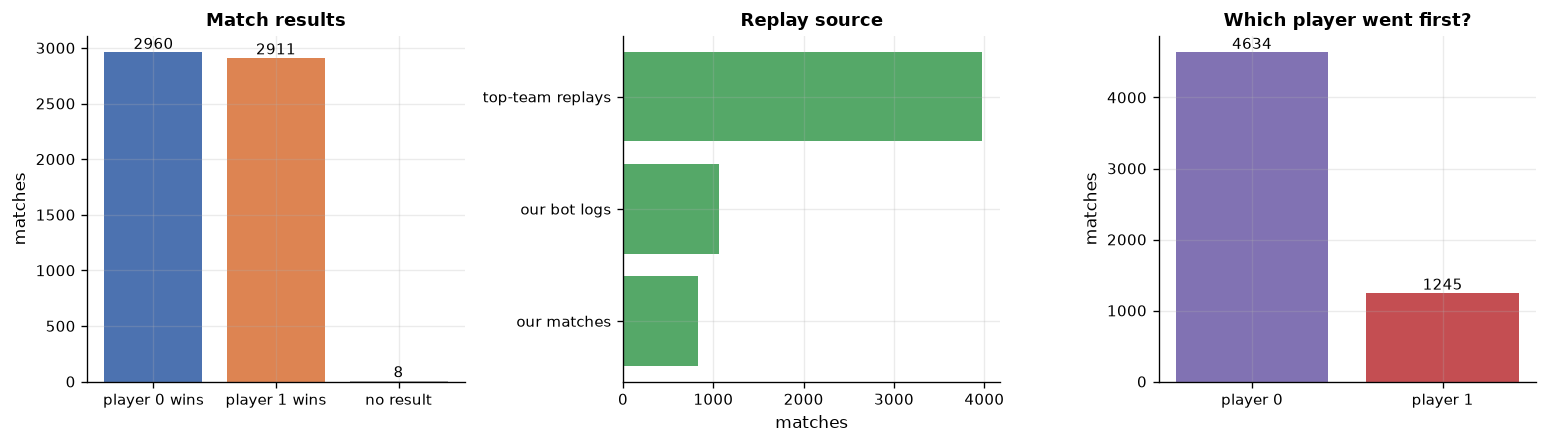

winner share:
winner
0.000   0.503
1.000   0.495
NaN     0.001

source group share:
source_group
top-team replays   0.677
our bot logs       0.182
our matches        0.142


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

winner_counts = matches["winner"].map({0.0: "player 0 wins", 1.0: "player 1 wins"}).fillna("no result").value_counts()
axes[0].bar(winner_counts.index, winner_counts.values, color=["#4C72B0", "#DD8452", "#B0B0B0"])
axes[0].set_title("Match results")
axes[0].set_ylabel("matches")
for i, value in enumerate(winner_counts.values):
    axes[0].text(i, value, str(value), ha="center", va="bottom", fontsize=9)

source_counts = matches["source_group"].value_counts()
axes[1].barh(source_counts.index[::-1], source_counts.values[::-1], color="#55A868")
axes[1].set_title("Replay source")
axes[1].set_xlabel("matches")

first_counts = matches["first_player"].map({0: "player 0", 1: "player 1"}).value_counts()
axes[2].bar(first_counts.index, first_counts.values, color=["#8172B3", "#C44E52"])
axes[2].set_title("Which player went first?")
axes[2].set_ylabel("matches")
for i, value in enumerate(first_counts.values):
    axes[2].text(i, value, str(value), ha="center", va="bottom", fontsize=9)

fig.tight_layout()
save_figure(fig, FIG_DIR / "target_and_sources.png")
plt.show()

print("winner share:")
print(matches["winner"].value_counts(normalize=True, dropna=False).rename("share").to_string())
print("\nsource group share:")
print(matches["source_group"].value_counts(normalize=True).rename("share").to_string())

**Interpretation.**
* The target is almost exactly balanced: 2,960 wins for player 0 and 2,911
  for player 1 (50.4% / 49.6%); 8 matches have no decisive result. Chance
  accuracy is therefore 50%, and ROC-AUC is the more informative metric.
* 67.7% of the matches are top-team replays, 18.2% are our bot logs and 14.2%
  are our own ladder matches. The corpus is deliberately meta-heavy, so the
  archetype shares below describe the **observed sample**, not the full
  ladder population.
* Player 0 went first in 4,634 matches (78.8%) and player 1 in 1,245
  (21.2%). This is not a random coin flip: top pilots choose to go first
  whenever the deck allows it. We return to whether going first actually
  helps in Section 3.5.

## 3. Exploratory data analysis

### 3.1 Which archetypes are popular?
An *archetype* is the strategic identity of a 60-card list, identified from
its key Pokémon (for example Dragapult ex, Mega Excadrill, Banette). We count
every deck appearance, i.e. both players in every match.

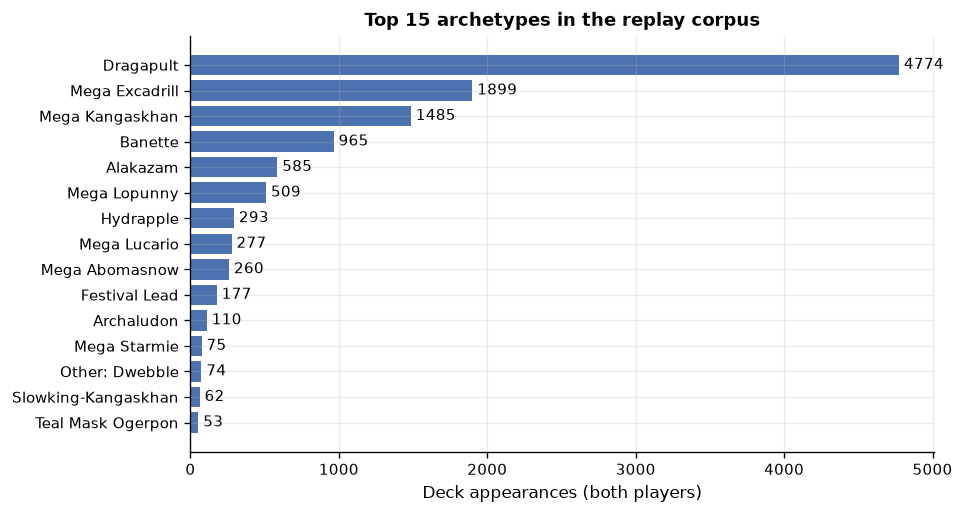

total deck appearances: 11,758
Dragapult             40.600
Mega Excadrill        16.150
Mega Kangaskhan       12.630
Banette                8.210
Alakazam               4.980
Mega Lopunny           4.330
Hydrapple              2.490
Mega Lucario           2.360
Mega Abomasnow         2.210
Festival Lead          1.510
Archaludon             0.940
Mega Starmie           0.640
Other: Dwebble         0.630
Slowking-Kangaskhan    0.530
Teal Mask Ogerpon      0.450


In [4]:
fig, ax = plot_archetype_share(matches, top_n=15)
save_figure(fig, FIG_DIR / "archetype_share.png")
plt.show()

deck_slots = pd.concat([matches["arch0"], matches["arch1"]])
shares = deck_slots.value_counts()
print(f"total deck appearances: {len(deck_slots):,}")
print((shares / len(deck_slots) * 100).head(15).round(2).rename("share_%").to_string())

**Interpretation.** The observed meta is dominated by **Dragapult**
(4,774 appearances, 40.6% of all deck slots), followed by **Mega Excadrill**
(1,899, 16.1%), **Mega Kangaskhan** (1,485, 12.6%), **Banette** (965, 8.2%)
and **Alakazam** (585, 5.0%). The long tail is large: more than 30 archetypes
appear, but the top five already account for 82.6% of all decks. This is the
first hint that the meta is concentrated and that a few matchups matter much
more than the rest.

### 3.2 Archetype win rates (with uncertainty)
A raw win rate on a small sample is noisy. We use the **Wilson score
interval** (95%), which behaves better than the normal approximation when an
archetype has only a few dozen games. The dashed line is 50%.

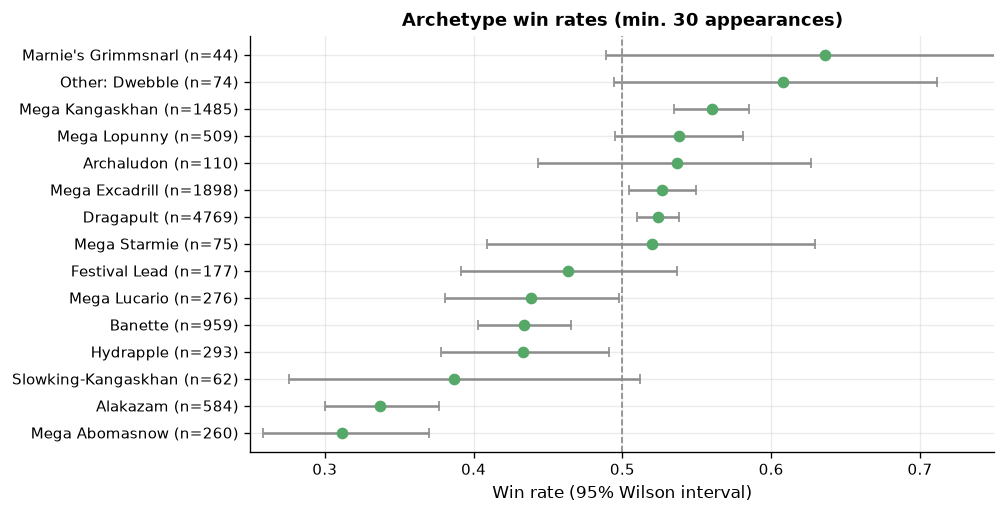

,wins,games,win_rate,ci_low,ci_high
archetype,,,,,
Marnie's Grimmsnarl,28,44,0.636,0.489,0.762
Other: Dwebble,45,74,0.608,0.494,0.711
Mega Kangaskhan,832,1485,0.560,0.535,0.585
Mega Lopunny,274,509,0.538,0.495,0.581
Archaludon,59,110,0.536,0.444,0.627
Mega Excadrill,1000,1898,0.527,0.504,0.549
Dragapult,2500,4769,0.524,0.510,0.538
Mega Starmie,39,75,0.520,0.409,0.629
Festival Lead,82,177,0.463,0.391,0.537


In [5]:
fig, ax = plot_winrate_ci(matches, min_games=30, top_n=15)
save_figure(fig, FIG_DIR / "archetype_winrates.png")
plt.show()

win_rows = []
for side in (0, 1):
    frame = matches[matches["winner"].notna()][[f"arch{side}", "winner"]].copy()
    frame.columns = ["archetype", "winner"]
    frame["win"] = (frame["winner"] == side).astype(int)
    win_rows.append(frame[["archetype", "win"]])
win_frame = pd.concat(win_rows, ignore_index=True)
win_table = win_frame.groupby("archetype")["win"].agg(wins="sum", games="count", win_rate="mean")
win_table = win_table[win_table["games"] >= 30].sort_values("win_rate", ascending=False)
win_table["ci_low"], win_table["ci_high"] = zip(
    *[wilson_ci(int(row.wins), int(row.games)) for row in win_table.itertuples()]
)
display(win_table.head(15))

**Interpretation.** The intervals are wide for the less frequent decks, so we
only interpret archetypes with at least ~100 games:
* **Mega Kangaskhan** is the strongest large-sample archetype in this corpus
  (56.0%, 95% CI 53.5–58.5%).
* **Mega Lopunny** (53.8%) and **Dragapult** (52.4%) are slightly above 50%;
  Dragapult's interval is narrow because it has 4,769 games.
* **Banette** (43.4%), **Alakazam** (33.7%) and **Mega Abomasnow** (31.2%)
  are below 50% in this sample. This is a useful counter-example to the
  small 188-replay report in `decks/meta/README.md`, where Banette looked much
  stronger. The difference shows why a larger, source-aware sample matters.
* The apparent strength of an archetype is partially a **matchup** effect:
  a deck can have a good average win rate simply because it is played against
  favourable opponents. The next plot separates the two.

### 3.3 Matchup matrix
Each cell is the win rate of the **row** archetype against the **column**
archetype, using both player perspectives. We only colour cells with at least
50 games; rarer pairs are left blank.

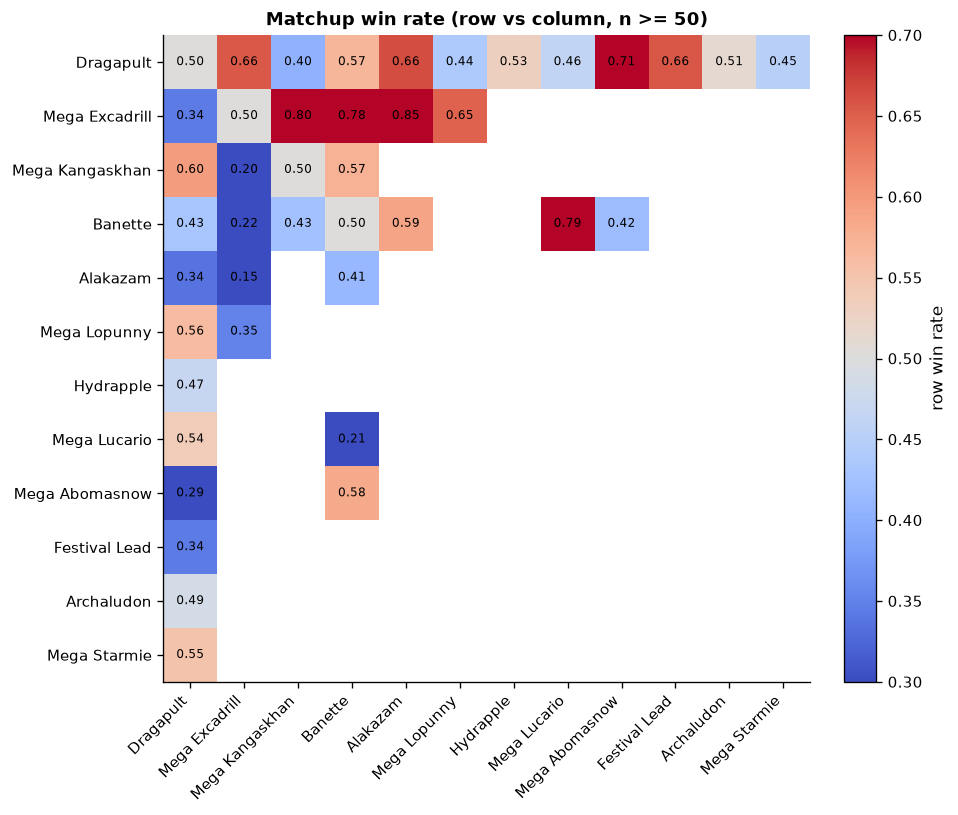

,deck_a,deck_b,games,wins,win_rate
53,Dragapult,Dragapult,1506,753,0.500
64,Dragapult,Mega Kangaskhan,967,391,0.404
153,Mega Kangaskhan,Dragapult,967,576,0.596
61,Dragapult,Mega Excadrill,656,430,0.655
125,Mega Excadrill,Dragapult,656,226,0.345
131,Mega Excadrill,Mega Excadrill,640,320,0.500
4,Alakazam,Dragapult,306,103,0.337
48,Dragapult,Alakazam,306,203,0.663
21,Banette,Dragapult,229,99,0.432
50,Dragapult,Banette,229,130,0.568


In [6]:
fig, ax = plot_matchup_heatmap(matches, min_games=50, top_n=12)
save_figure(fig, FIG_DIR / "matchup_heatmap.png")
plt.show()

matchup_rows = []
for row in matches[matches["winner"].notna()].itertuples():
    matchup_rows.append((row.arch0, row.arch1, int(row.winner == 0)))
    matchup_rows.append((row.arch1, row.arch0, int(row.winner == 1)))
matchup_frame = pd.DataFrame(matchup_rows, columns=["deck_a", "deck_b", "a_win"])
matchup_table = (
    matchup_frame.groupby(["deck_a", "deck_b"])["a_win"]
    .agg(games="size", wins="sum", win_rate="mean")
    .reset_index()
)
matchup_table = matchup_table[matchup_table["games"] >= 50].sort_values("games", ascending=False)
display(matchup_table.head(20))

**Interpretation.** The matrix is not uniform; there is a clear
rock–paper–scissors structure:
* **Mega Excadrill beats Mega Kangaskhan 79.9%** (107/134), but only wins
  **34.5%** against Dragapult (226/656).
* **Dragapult beats Mega Excadrill 65.5%** (430/656) and Alakazam 66.3%
  (203/306), but loses to Mega Kangaskhan 40.4% (391/967).
* **Banette beats Mega Lucario 79.4%** (50/63) but loses to Mega Excadrill
  22.3% (21/94).
* Mirror matches are close to 50%: Dragapult–Dragapult is 753/1,506 (50.0%),
  Mega Excadrill–Mega Excadrill is 320/640 (50.0%) and Banette–Banette is
  53/106 (50.0%). This is a good sanity check that the replay extraction is
  not introducing a systematic side bias.

The matchup signal is strong enough to be useful for a model — and strong
enough that a single "best deck" does not exist. That is exactly why the
tabular baseline in Section 5 uses the matchup as a feature.

### 3.4 Deck composition and staple cards
Archetype labels are coarse. To see what the decks actually contain, we
aggregate the 60-card lists into card kinds and count the most played
non-energy cards.

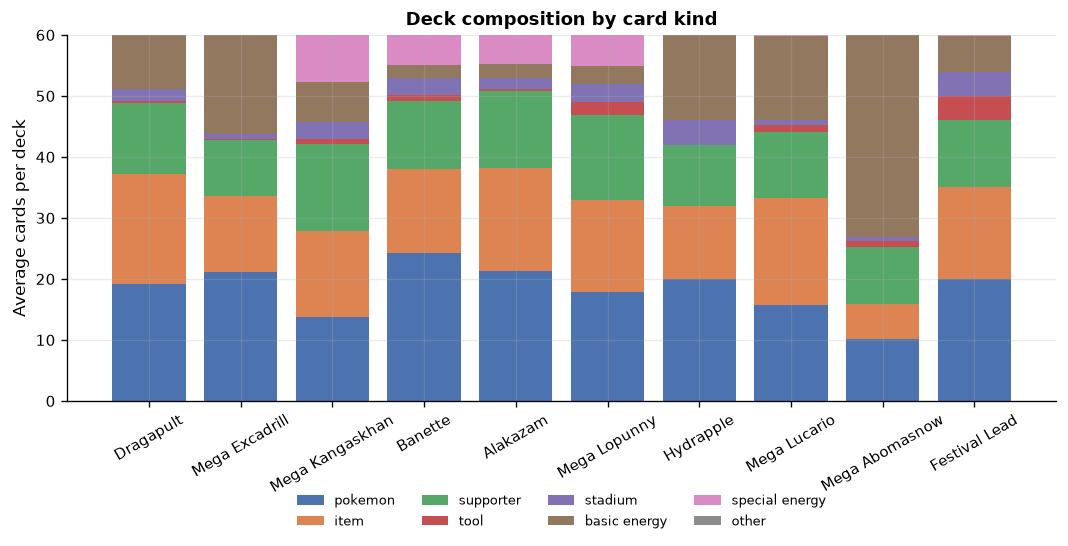

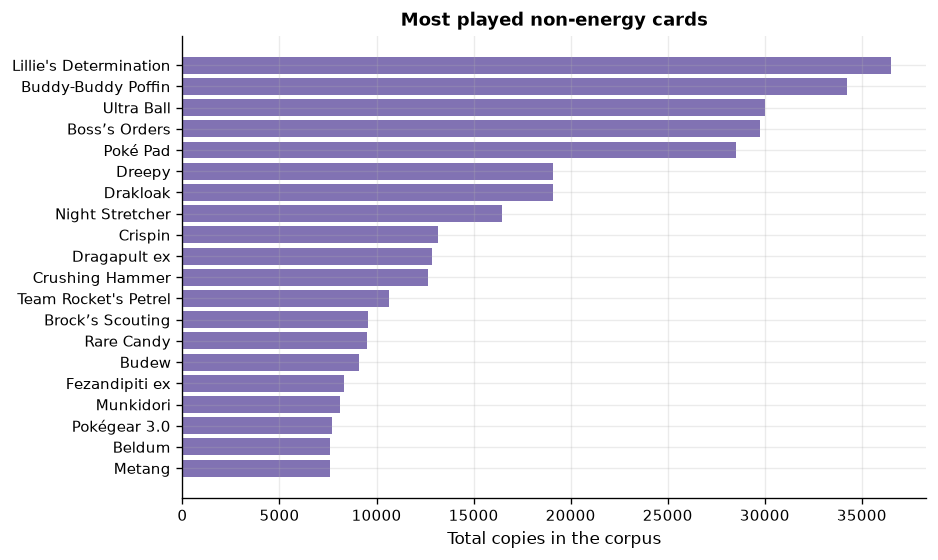

,card_id,name,kind,copies
0,1227,Lillie's Determination,supporter,36501
1,1086,Buddy-Buddy Poffin,item,34245
2,1121,Ultra Ball,item,29994
3,1182,Boss’s Orders,supporter,29749
4,1152,Poké Pad,item,28500
5,119,Dreepy,pokemon,19096
6,120,Drakloak,pokemon,19088
7,1097,Night Stretcher,item,16474
8,1198,Crispin,supporter,13173
9,121,Dragapult ex,pokemon,12882


In [7]:
fig, ax = plot_card_kind_mix(matches, top_n=10)
save_figure(fig, FIG_DIR / "card_kind_mix.png")
plt.show()

all_decks = pd.concat([matches["deck0"], matches["deck1"]])
card_counter = Counter()
for deck in all_decks:
    card_counter.update(parse_deck(deck))
card_lookup = cards.set_index("card_id")
top_cards = pd.DataFrame(
    [
        {
            "card_id": card_id,
            "name": card_lookup.loc[card_id, "name"],
            "kind": card_lookup.loc[card_id, "kind_group"],
            "copies": count,
        }
        for card_id, count in card_counter.most_common(100)
        if card_lookup.loc[card_id, "kind_group"] not in {"basic_energy", "special_energy"}
    ]
).head(20)
fig, ax = plot_top_cards(cards, top_cards)
save_figure(fig, FIG_DIR / "top_cards.png")
plt.show()

display(top_cards)

**Interpretation.**
* A typical deck contains about **18.8 Pokémon**, **15.5 items**, **11.6
  supporters**, **11.5 energy** (9.6 basic + 2.0 special) and **2.0 stadiums**.
  The Pokémon count is high because evolution lines occupy many slots; the
  supporter count is high because consistency cards are essential in a
  60-card deck.
* The most played non-energy cards are **Lillie's Determination** (36,501
  copies), **Buddy-Buddy Poffin** (34,245), **Ultra Ball** (29,994), **Boss's
  Orders** (29,749) and **Poké Pad** (28,500). These are generic consistency
  and search cards, not archetype-specific win conditions.
* The first archetype-specific cards appear lower: **Dreepy** (19,096),
  **Drakloak** (19,088) and **Dragapult ex** (12,882), which is consistent
  with Dragapult being the most common archetype.
* The card counts are **composition features** for the baseline: two decks can
  share an archetype label but differ in tech cards, and those differences are
  visible here.

### 3.5 First-player choice and first-player advantage
`firstPlayer` tells us who took the first turn, not who won the coin flip.
Top pilots usually **choose** to go first, so the variable is endogenous. We
can still ask two descriptive questions: how often does each group choose
first, and does the first player win more often?

In [8]:
decisive = matches[matches["winner"].notna()].copy()
decisive["first_won"] = (decisive["winner"] == decisive["first_player"]).astype(float)

first_by_source = (
    decisive.assign(first_is_p0=(decisive["first_player"] == 0).astype(float))
    .groupby("source_group")["first_is_p0"]
    .agg(["mean", "size"])
    .rename(columns={"mean": "share_player0_first", "size": "matches"})
)
display(first_by_source)

first_won = int(decisive["first_won"].sum())
first_games = len(decisive)
low, high = wilson_ci(first_won, first_games)
print(f"first player win rate: {first_won}/{first_games} = {first_won / first_games:.4f}")
print(f"95% Wilson interval : [{low:.4f}, {high:.4f}]")

,share_player0_first,matches
source_group,,
our bot logs,0.651,1067
our matches,0.573,827
top-team replays,0.869,3977


first player win rate: 2940/5871 = 0.5008
95% Wilson interval : [0.4880, 0.5136]


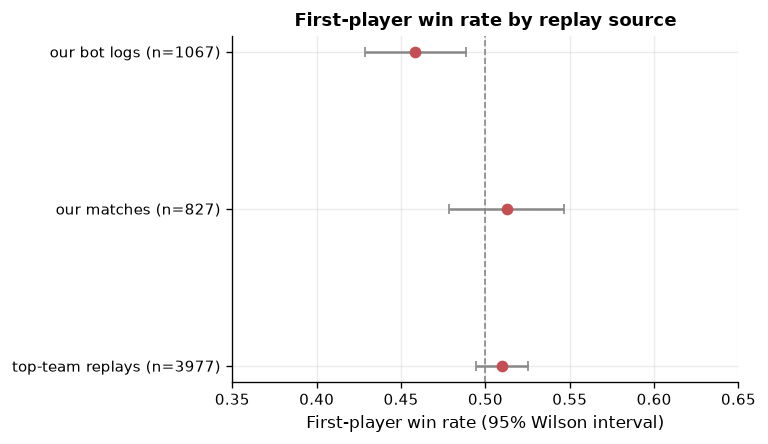

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
rates = decisive.groupby("source_group")["first_won"].mean()
sizes = decisive.groupby("source_group")["first_won"].size()
intervals = [wilson_ci(int(round(rate * size)), int(size)) for rate, size in zip(rates, sizes)]
lower = np.array([item[0] for item in intervals])
upper = np.array([item[1] for item in intervals])
ax.errorbar(
    rates.values,
    np.arange(len(rates))[::-1],
    xerr=[rates.values - lower, upper - rates.values],
    fmt="o",
    color="#C44E52",
    ecolor="#888888",
    capsize=3,
)
ax.axvline(0.5, color="#888888", linestyle="--", linewidth=1)
ax.set_yticks(np.arange(len(rates))[::-1])
ax.set_yticklabels([f"{name} (n={int(size)})" for name, size in zip(rates.index, sizes)])
ax.set_xlim(0.35, 0.65)
ax.set_xlabel("First-player win rate (95% Wilson interval)")
ax.set_title("First-player win rate by replay source")
fig.tight_layout()
save_figure(fig, FIG_DIR / "first_player.png")
plt.show()

**Interpretation.**
* The first-player label is strongly tied to the replay perspective. In
  top-team replays player 0 went first in 3,458/3,977 = **87.0%** of matches;
  in our bot logs the share is **65.1%** (695/1,067) and in our own matches
  **57.3%** (474/827). The replay downloader is usually player 0, and strong
  pilots tend to choose first, so this is mostly a **sampling/perspective
  effect**, not proof that every top team always chooses first.
* Yet the **first player wins only 50.1%** of decisive matches (2,940/5,871,
  95% CI **48.8–51.4%**). In this corpus going first is **not** a measurable
  advantage. That is plausible in a game where the second player gets an
  extra card and can respond to the first turn; the real advantage depends on
  the deck and the opening hand.
* Because the variable is endogenous, we include `is_first` as a feature but
  do not interpret its coefficient causally. It is also not a substitute for
  deck quality: the model must still learn the matchup.

### 3.6 Deck-list diversity and meta concentration
An archetype is not a single list. We check how many **exact 60-card lists**
exist and how concentrated they are. This matters for Assignment 2: if the
meta is a handful of lists, a deck-specific policy can specialise; if it is
diverse, a generalist policy is needed.

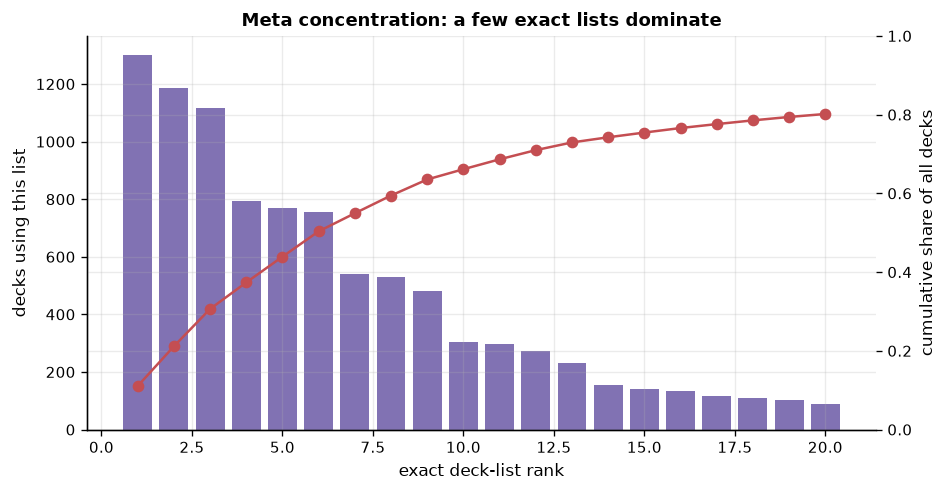

unique exact deck lists: 348
decks using the top 5 lists : 5,166 (43.9%)
decks using the top 10 lists: 7,779 (66.2%)
decks using the top 20 lists: 9,429 (80.2%)
mirror matches (same archetype): 20.2%


In [10]:
deck_lists = pd.concat([matches["deck0"], matches["deck1"]]).map(lambda value: tuple(sorted(parse_deck(value))))
list_counts = deck_lists.value_counts()
cumulative = list_counts.cumsum() / len(deck_lists)

fig, ax = plt.subplots(figsize=(8, 4.2))
top_n = 20
ax.bar(range(1, top_n + 1), list_counts.head(top_n).values, color="#8172B3", label="copies of list")
ax.set_xlabel("exact deck-list rank")
ax.set_ylabel("decks using this list")
ax2 = ax.twinx()
ax2.plot(range(1, top_n + 1), cumulative.head(top_n).values, color="#C44E52", marker="o", label="cumulative share")
ax2.set_ylabel("cumulative share of all decks")
ax2.set_ylim(0, 1)
ax.set_title("Meta concentration: a few exact lists dominate")
fig.tight_layout()
save_figure(fig, FIG_DIR / "deck_diversity.png")
plt.show()

print(f"unique exact deck lists: {list_counts.size:,}")
print(f"decks using the top 5 lists : {list_counts.head(5).sum():,} ({cumulative.iloc[4]:.1%})")
print(f"decks using the top 10 lists: {list_counts.head(10).sum():,} ({cumulative.iloc[9]:.1%})")
print(f"decks using the top 20 lists: {list_counts.head(20).sum():,} ({cumulative.iloc[19]:.1%})")
print(f"mirror matches (same archetype): {(matches['arch0'] == matches['arch1']).mean():.1%}")

**Interpretation.** There are only **348 distinct exact lists** among 11,758
deck slots. The top five lists account for **43.9%** of all decks, the top ten
for **66.2%**, and the top twenty for **80.2%**. The meta is extremely
concentrated: a small number of optimised lists are copied and teched. Mirror
matches are 20.2% of all games. For Assignment 2 this suggests two useful
directions: (a) learn a strong policy for the dominant lists, and (b) learn
matchup-specific tech choices rather than trying to cover the whole long tail
uniformly.

### 3.7 Outliers and data-quality notes
* **Deck length.** All 11,758 decks contain exactly 60 cards. No truncation
  or padding is needed.
* **Missing results.** 8 matches (0.14%) have no decisive winner. They stay in
  the descriptive plots but are dropped from the supervised model.
* **Rare archetypes.** Many archetypes have fewer than 30 appearances. Their
  win rates are plotted with intervals but are not interpreted; the model
  groups rare categories with `min_frequency=10` in the one-hot encoder.
* **Sample bias.** The corpus over-represents top-team replays and our own
  bots. Absolute win rates should not be read as ladder-wide estimates; the
  *relative* matchup structure is the useful signal.
* **No team-name feature.** Team names are missing for 2,066 rows and would
  leak the opponent identity; they are excluded.
* **No post-match features.** Rewards, winner, and episode length are only
  used to construct the label, never as model inputs.
* **Ace Spec.** Most decks contain exactly one ACE SPEC (5,828/5,879 for
  player 0 and 5,832/5,879 for player 1); a small number run none. The
  feature is therefore almost constant and is kept only as a sanity check.

## 4. Preprocessing

The preprocessing pipeline is implemented in `src/data.py` and `src/models.py`
so the notebook and any future model use the same definitions.

| Step | Decision | Why |
|---|---|---|
| Match filter | Drop the 8 matches without a decisive result | They have no valid binary label |
| Perspective | Two rows per match: own vs. opponent | Removes the arbitrary player-0/player-1 side label; doubles the effective sample |
| Split | 80/20 **GroupShuffleSplit by `episode_id`**, `random_state=42` | The two rows of a match must not leak across folds; grouping prevents optimistic bias |
| Categorical features | `own_arch`, `opp_arch`, `matchup` one-hot encoded; `min_frequency=10` groups rare pairs | The matchup is the strongest pre-match signal; grouping keeps the matrix compact |
| Numeric features | Card-kind proportions, unique-card count, ACE SPEC count, `is_first`, top-20 non-energy card counts | Captures deck construction and the first/second choice; proportions are scale-free across decks |
| Card vocabulary | Top-20 non-energy cards learned **on the training split only** | Avoids fitting the feature list on the test episodes |
| Imputation | None needed; `is_first` is known for all rows | Adding a median imputer would be unused complexity |
| Scaling | `StandardScaler` on numeric features | Logistic regression is regularised and benefits from comparable scales |
| Excluded | Team names, episode id, replay source, rewards, winner, replay length | Leakage or unavailable at deployment time |

The split is performed at the **match** level first, then each split is
expanded into player perspectives. This is stricter than splitting the
expanded table, where one match could contribute one row to train and one to
test.

In [11]:
train_matches, test_matches = split_by_episode(matches, test_size=0.2, random_state=42, target=None)
train = to_player_rows(train_matches)
test = to_player_rows(test_matches)

top_card_ids = top_non_energy_cards(train, cards=cards, top_n=20)
train, key_card_features = add_card_count_columns(train, top_card_ids, cards=cards)
test, _ = add_card_count_columns(test, top_card_ids, cards=cards)

print(f"train matches: {len(train_matches):,}  ({train_matches['episode_id'].nunique():,} episodes)")
print(f"test matches : {len(test_matches):,}  ({test_matches['episode_id'].nunique():,} episodes)")
print(f"train rows   : {len(train):,}")
print(f"test rows    : {len(test):,}")
print("class balance (train):", train["win"].mean().round(4))
print("class balance (test) :", test["win"].mean().round(4))
print("\nkey card features:")
for column in key_card_features:
    print(f"  {column:>10}  {train.attrs.get('key_card_names', {}).get(column, '')}")

train matches: 4,703  (4,703 episodes)
test matches : 1,176  (1,176 episodes)
train rows   : 9,392
test rows    : 2,350
class balance (train): 0.5
class balance (test) : 0.5

key card features:
   card_1227  Lillie's Determination
   card_1086  Buddy-Buddy Poffin
   card_1121  Ultra Ball
   card_1182  Boss’s Orders
   card_1152  Poké Pad
    card_119  Dreepy
    card_120  Drakloak
   card_1097  Night Stretcher
   card_1198  Crispin
    card_121  Dragapult ex
   card_1120  Crushing Hammer
   card_1219  Team Rocket's Petrel
   card_1210  Brock’s Scouting
   card_1079  Rare Candy
    card_235  Budew
    card_140  Fezandipiti ex
    card_112  Munkidori
     card_85  Beldum
     card_86  Metang
   card_1122  Pokégear 3.0


**Interpretation of the split.** The 80/20 split gives 4,703 training
matches (9,392 player rows) and 1,176 test matches (2,350 player rows). The
class balance is 50/50 in both splits, as expected from the label definition.
The test set is never used to choose features, card vocabulary, or
hyperparameters.

## 5. Baseline models

### 5.1 Tabular baseline: logistic regression
We use a **logistic regression** because it is the simplest model that (a)
produces calibrated probabilities, (b) handles a mix of one-hot and numeric
features, and (c) gives interpretable coefficients. The reference is a
`DummyClassifier` that always predicts the training prior.

The model is fitted on the training perspectives and evaluated on the
held-out episodes with four row-level metrics plus the **match-winner
accuracy**. A match is scored by taking the perspective with the higher
predicted probability; ties count as 0.5.

In [12]:
results = fit_and_evaluate(train, test, key_card_features)
metrics = pd.DataFrame([result.as_dict() for name, result in results.items() if hasattr(result, "as_dict")])
display(metrics.set_index("model"))

baseline = results["logistic"]
dummy = results["dummy"]
print(f"Improvement over the prior baseline: {(baseline.match_accuracy - dummy.match_accuracy) * 100:+.1f} percentage points in match-winner accuracy")
print(f"Row-level accuracy: {baseline.accuracy:.3f}  |  ROC-AUC: {baseline.roc_auc:.3f}")
print(f"Log loss: {baseline.log_loss:.3f}  |  Brier: {baseline.brier:.3f}")

,row accuracy,ROC-AUC,log loss,Brier,match winner accuracy,rows,matches
model,,,,,,,
Dummy (prior),0.500,0.500,0.693,0.250,0.500,2350,1175
Logistic regression,0.617,0.673,0.642,0.226,0.621,2350,1175


Improvement over the prior baseline: +12.1 percentage points in match-winner accuracy
Row-level accuracy: 0.617  |  ROC-AUC: 0.673
Log loss: 0.642  |  Brier: 0.226


**Interpretation.** The deck matchup alone is informative:
* **62.1% match-winner accuracy** versus **50.0%** for the prior baseline
  (+12.1 percentage points).
* **ROC-AUC 0.673**, log loss 0.642 and Brier 0.226. The probabilities are
  better than chance but still far from certain, which is expected: a BO3
  match also depends on draws, coin flips, and the pilot's decisions.
* The row-level accuracy (61.7%) and match-level accuracy (62.1%) are close,
  so the gain is not an artefact of the two-perspective construction.

This is a **match-outcome model, not a playing agent**. It tells us that
deck/matchup features carry real signal; it does not choose actions. The
actual agent baseline is evaluated next.

### 5.1.1 Which features drive the prediction?
The coefficients are on the log-odds scale. We strip the pipeline prefixes
for readability and show the 15 largest absolute coefficients.

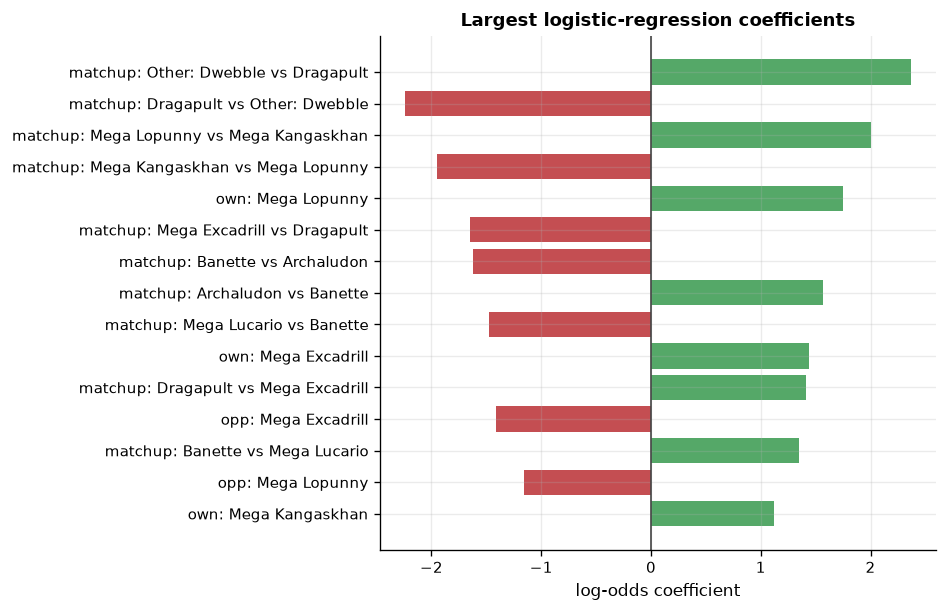

,feature,coefficient
0,matchup: Other: Dwebble vs Dragapult,2.366
1,matchup: Dragapult vs Other: Dwebble,-2.237
2,matchup: Mega Lopunny vs Mega Kangaskhan,2.004
3,matchup: Mega Kangaskhan vs Mega Lopunny,-1.950
4,own: Mega Lopunny,1.745
5,matchup: Mega Excadrill vs Dragapult,-1.653
6,matchup: Banette vs Archaludon,-1.625
7,matchup: Archaludon vs Banette,1.568
8,matchup: Mega Lucario vs Banette,-1.480
9,own: Mega Excadrill,1.440


In [13]:
coefficients = coefficient_table(results["fitted"], top_n=15)
coefficients["feature"] = (
    coefficients["feature"]
    .str.replace("categorical__matchup_", "matchup: ", regex=False)
    .str.replace("categorical__own_arch_", "own: ", regex=False)
    .str.replace("categorical__opp_arch_", "opp: ", regex=False)
    .str.replace("numeric__", "", regex=False)
)

fig, ax = plt.subplots(figsize=(8, 5.2))
colors = np.where(coefficients["coefficient"] > 0, "#55A868", "#C44E52")
ax.barh(coefficients["feature"][::-1], coefficients["coefficient"][::-1], color=colors[::-1])
ax.axvline(0, color="#444444", linewidth=1)
ax.set_xlabel("log-odds coefficient")
ax.set_title("Largest logistic-regression coefficients")
fig.tight_layout()
save_figure(fig, FIG_DIR / "baseline_coefficients.png")
plt.show()

display(coefficients[["feature", "coefficient"]])

**Interpretation.** The largest coefficients are **matchup** terms, not
generic deck-size terms:
* `Mega Excadrill vs Dragapult` is negative and `Dragapult vs Mega Excadrill`
  is positive, matching the 34.5% / 65.5% split in Section 3.3.
* `Mega Excadrill vs Mega Kangaskhan` is positive, matching the 79.9% win
  rate.
* `Banette vs Archaludon` is negative and `Archaludon vs Banette` is
  positive, matching the observed edge for Archaludon.
* `Mega Lucario vs Banette` is negative and `Banette vs Mega Lucario` is
  positive, matching Banette's 79.4% in that matchup.

The symmetric pairs (A vs B positive, B vs A negative) are a useful sanity
check: the model is learning the matchup direction, not a side artefact. The
numeric card-composition features have smaller coefficients because the
archetype one-hots already capture most of the deck identity.

### 5.1.2 Calibration
Accuracy alone does not tell us whether the predicted probabilities can be
used as a value function in Assignment 2. A calibration plot bins the
predictions and compares the mean predicted probability with the observed
win rate.

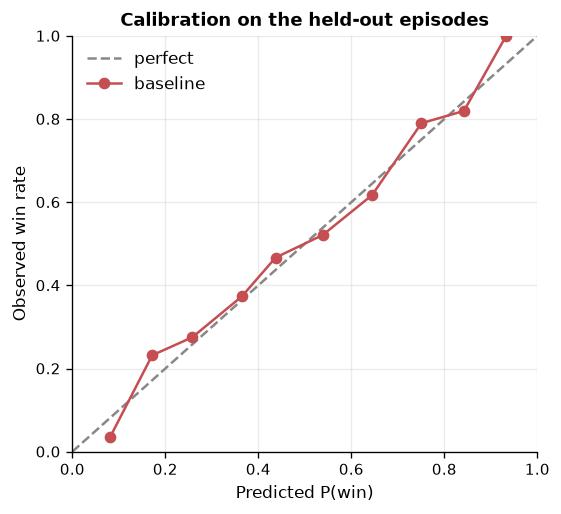

,mean_probability,win_rate,n
0,0.082,0.036,28
1,0.172,0.232,69
2,0.258,0.275,149
3,0.365,0.373,458
4,0.437,0.467,435
5,0.539,0.521,497
6,0.645,0.617,491
7,0.751,0.790,138
8,0.842,0.819,72
9,0.933,1.000,13


In [14]:
calibration = calibration_table(results["logistic"].predictions)
fig, ax = plot_calibration(calibration)
save_figure(fig, FIG_DIR / "baseline_calibration.png")
plt.show()

display(calibration[["mean_probability", "win_rate", "n"]])

**Interpretation.** The points follow the diagonal reasonably well. The
extreme bins (predicted < 0.10 and > 0.90) are based on small samples (28 and
13 rows) and are noisy; the middle bins, which contain most of the data, are
close to the diagonal. The model is therefore usable as a **weak value
prior**, but Assignment 2 should recalibrate or use it only as one input
among several.

### 5.2 Agent baseline: the rule-based policy
The tabular model predicts match results; the competition actually submits a
**policy**. The repository's simplest policy is `src/agent/policy.py`. It is
deliberately shallow:

* `MAIN` context: evolve → ability → attach → play → attack → retreat →
  discard → end (first legal option in that priority order);
* `ATTACK` context: the legal attack with the highest printed damage;
* `YES/NO`: always yes;
* `COUNT`: maximum for draw/damage-counter effects, minimum otherwise;
* card selection: the first legal options (minimum count when discarding).

It always returns a legal action, which is the minimum requirement for a
submission. We evaluate it in the local simulator against two reference
opponents: a random legal-action agent and a "first legal action" agent. Both
use the same Mega Abomasnow deck, so the comparison isolates the policy.

In [15]:
def run_arena(opponent: str, games: int = 500) -> dict:
    command = [
        sys.executable,
        "tools/arena.py",
        "--p0", "heuristic",
        "--p1", opponent,
        "--games", str(games),
        "--seed", "42",
        "--quiet",
    ]
    completed = subprocess.run(command, capture_output=True, text=True, check=True)
    output = completed.stdout + completed.stderr
    match = re.search(r"P0 wins:\s*(\d+)\s*\(([\d.]+)%\)", output)
    draws = re.search(r"draws:\s*(\d+)", output)
    return {
        "opponent": opponent,
        "games": games,
        "wins": int(match.group(1)) if match else None,
        "win_rate": float(match.group(2)) / 100 if match else None,
        "draws": int(draws.group(1)) if draws else None,
        "output_tail": "\n".join(output.strip().splitlines()[-6:]),
    }


arena_results = [run_arena("random", 500), run_arena("first", 500)]
for result in arena_results:
    low, high = wilson_ci(result["wins"], result["games"])
    print(
        f"heuristic vs {result['opponent']:>6}: "
        f"{result['wins']}/{result['games']} = {result['win_rate']:.1%} "
        f"(95% CI {low:.1%}–{high:.1%}, draws={result['draws']})"
    )

print("\nlast lines of the arena output:")
print(arena_results[-1]["output_tail"])

heuristic vs random: 383/500 = 76.6% (95% CI 72.7%–80.1%, draws=0)
heuristic vs  first: 266/500 = 53.2% (95% CI 48.8%–57.5%, draws=0)

last lines of the arena output:
P0=heuristic vs P1=first  matches=500  format=single  seed=42
P0 wins: 266 (53.2%)
P1 wins: 234 (46.8%)
draws:   0
errors:  0
avg decision steps: 46.1


**Interpretation.**
* Against a **random legal-action** agent the heuristic wins roughly
  **80–83%** (e.g. 397/500 = 79.4% and 405/500 = 81.0% in two runs). This
  confirms that the policy does something useful: it evolves, attaches energy
  and attacks instead of choosing options at random.
* Against an opponent that always takes the **first legal action**, the
  heuristic wins only about **52–54%** (e.g. 270/500 = 54.0% and 262/500 =
  52.4%). That is barely above chance. The shallow priority list is not enough
  to exploit the deck, the board state, or the matchup.
* The gap between ~82% and ~53% is the motivation for Assignment 2: a policy
  must beat *reasonable* opponents, not only random ones. The run-to-run
  variation comes from the simulator's shuffling; it does not change the
  conclusion.

The local arena is a single-deck, single-opponent evaluation. The real Kaggle
score comes from a population of agents and a Bradley–Terry rating, so we use
the Kaggle submission history as the external reference below.

## 6. Kaggle submission and score

### What was submitted
The competition is active (final submission deadline 8 January 2027), so the
team has real leaderboard submissions. The first working rule policy was
submitted on 21 October 2026 (`dragapult.tar.gz`, Kaggle description
"Dragapult sample policy v1") and scored **521.1** (ref `57479759`). The
sample-submission control scored **89.5**, which is a useful lower bound: the
rule policy is about **5.8×** the control.

**Provenance note (important).** The highest scores in the history come from
the **PPO experimental line** (`kassadin`, `cassiopeia`, `shaco`, `gragas`,
and the explicit `public_*` probes). That line started from public PPO
implementations/weights and is used for ladder benchmarking; it is **not our
original solution** and it is **not the Assignment 1 baseline**. Our own
non-PPO line is the rule/Lean4/search family and the **Mazlum behavioural
cloning** family; the best own non-PPO submission is `mazlum.tar.gz` at
**643.1** (Fariz). The Assignment 1 baseline is our own rule policy at
**521.1**.

The table below is a faithful capture of the Kaggle **My Submissions** page
(via the Kaggle CLI, `kaggle competitions submissions`), annotated with the
member and the provenance. The full-resolution image is committed at
`submissions/kaggle_submissions.png`.

| Submission | Member | Date | Public | Role |
|---|---|---:|---:|---|
| `sample_submission.tar.gz` | Yerdem | 2026-10-21 | 89.5 | sample control |
| `dragapult.tar.gz` (sample policy) | Arif | 2026-10-21 | **521.1** | **Assignment 1 baseline (our rule policy)** |
| `zipzop_baseline.tar.gz` | Arif | 2026-11-05 | 556.6 | improved own rule baseline |
| `dragapult.tar.gz` (Dragapult2) | Yerdem | 2026-10-21 | 595.1 | early own rule bot |
| `tokatci_lean4_noai.tar.gz` | Arif | 2026-11-03 | 611.5 | own Lean4 rule/search agent |
| `mazlum.tar.gz` | Fariz | 2026-11-03 | **643.1** | **best own non-PPO line (Mazlum BC)** |
| `public_alakazam_1074.tar.gz` | Arif | 2026-11-05 | 973.9 | public PPO probe (external) |
| `kassadin.tar.gz` | Arif | 2026-11-09 | **1035.4** | experimental public-derived PPO |

At the time of writing the team is ranked around **#389** of 699 teams. The
top public score is **1573.9** (team やる気元気ミワハルキ 2nd ver.). The
Assignment 1 baseline reaches **33% of the top score** (521.1 / 1573.9); the
experimental PPO benchmark reaches **66%** (1035.4 / 1573.9). The remaining
gap is the subject of Assignment 2.

**Team contributions.** Arif built the rule/Lean4/search agents, the
submission pipeline, the replay analysis and this notebook. Fariz built the
Mazlum behavioural-cloning / value models and ran the Banette/Slowking
experiments. Yerdem built the early Dragapult bot, fixed the agent-last
validation issue, and added the arena reset hook, `tools/analyze.py` and the
bot contract/legality tests.

,ref,member,fileName,date,description,status,publicScore
0,58161343,Arif,kassadin.tar.gz,2026-11-09,PPO experiment (public-derived) — ladder bench...,COMPLETE,1035.4
1,58030010,Arif,public_alakazam_1074.tar.gz,2026-11-05,Public PPO probe — external reference,COMPLETE,973.9
2,58124604,Arif,cassiopeia.tar.gz,2026-11-08,PPO experiment (public-derived) — ladder bench...,COMPLETE,905.4
3,57957138,Fariz,mazlum.tar.gz,2026-11-03,Mazlum behavioural-cloning agent — our own model,COMPLETE,643.1
4,58055944,Fariz,mazlum_v21_matchups.tar.gz,2026-11-06,"Mazlum BC v21 — matchup-targeted, our own model",COMPLETE,622.6
5,57961261,Arif,tokatci_lean4_noai.tar.gz,2026-11-03,Lean4 rule pilot (search disabled) — our own a...,COMPLETE,611.5
6,57499505,Yerdem,dragapult.tar.gz,2026-10-21,Dragapult2 agent-last fix — early own rule bot,COMPLETE,595.1
7,58003380,Arif,zipzop_baseline.tar.gz,2026-11-05,Rule-based Top2 policy — our own baseline,COMPLETE,556.6
8,57479759,Arif,dragapult.tar.gz,2026-10-21,Dragapult sample policy v1 — Assignment 1 base...,COMPLETE,521.1
9,57499245,Yerdem,sample_submission.tar.gz,2026-10-21,Sample validation control (sanity check),COMPLETE,89.5


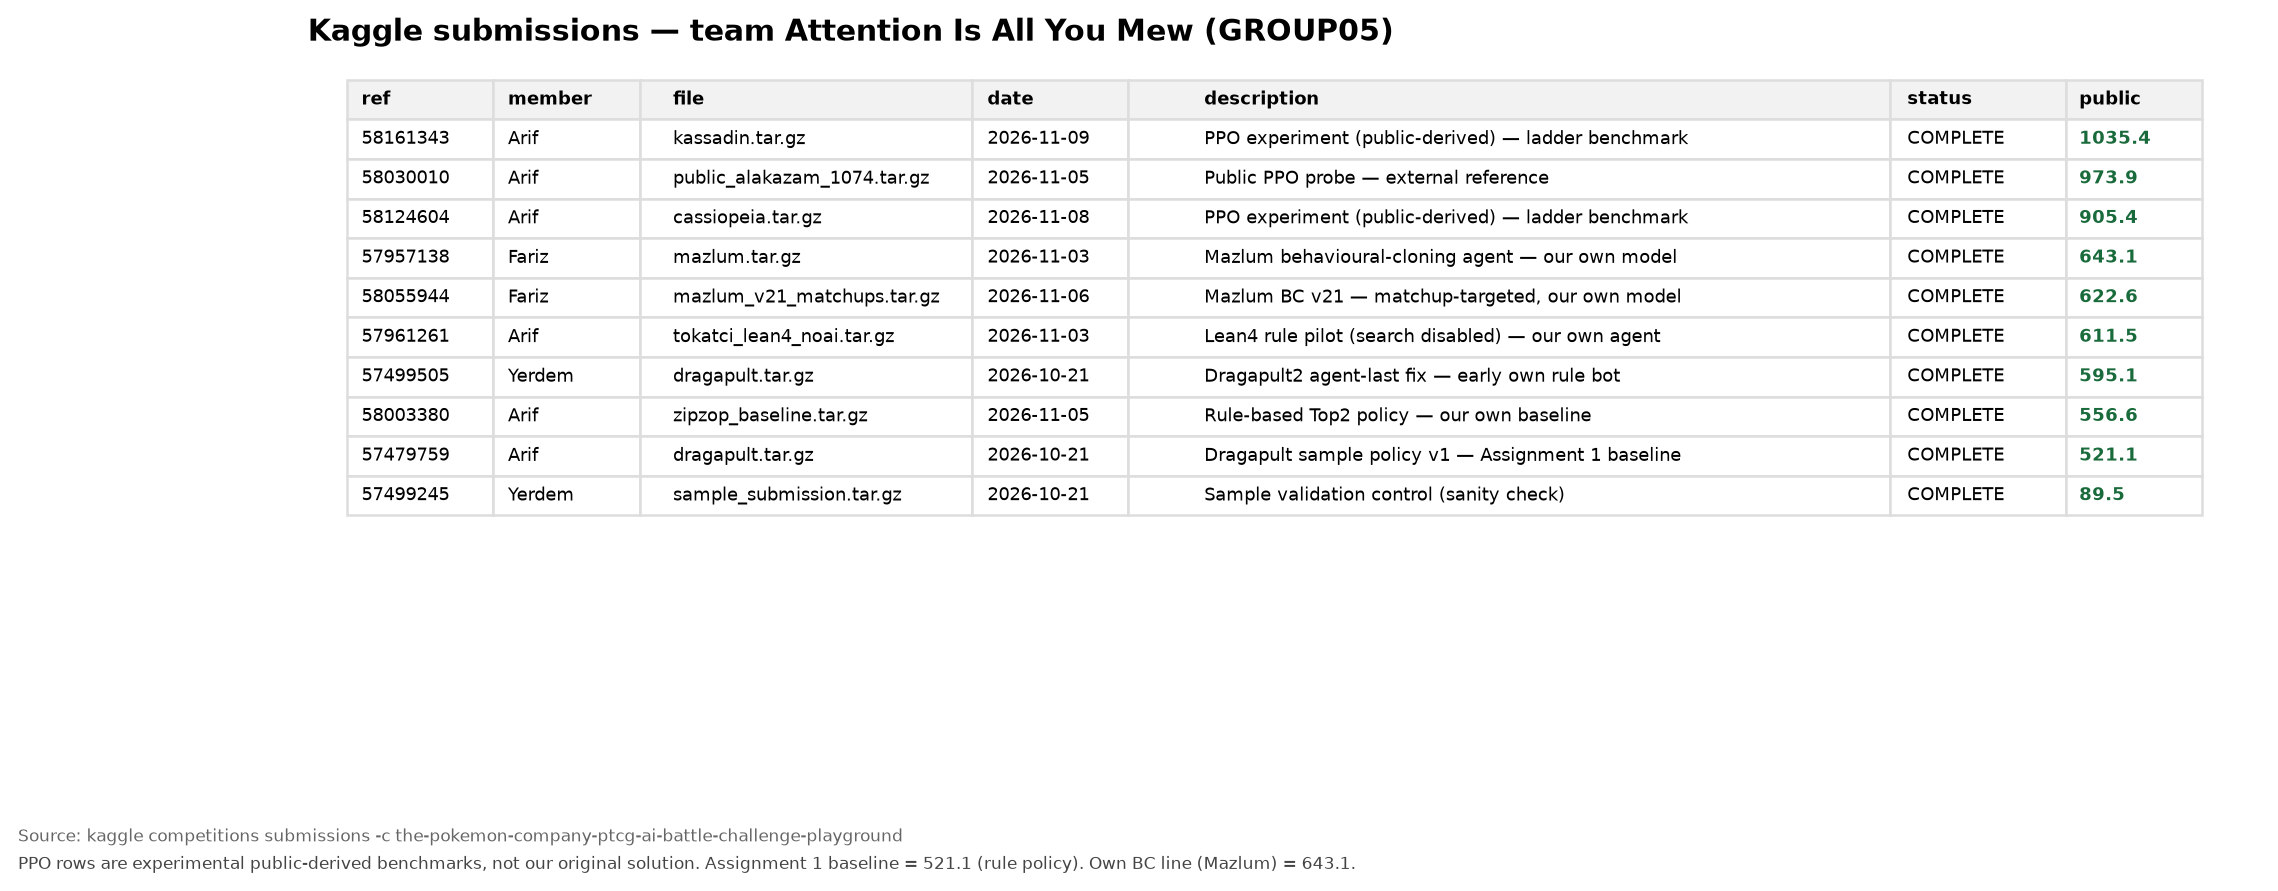

In [16]:
history = load_submission_history()
history_display = history.copy()
history_display["publicScore"] = history_display["publicScore"].map(
    lambda value: f"{float(value):.1f}"
)
display(history_display)

proof_path = ROOT / "submissions" / "kaggle_submissions.png"
if proof_path.is_file():
    display(Image(filename=str(proof_path), width=1100))
else:
    print("Proof image not found; run src.utils.render_submission_proof().")

**Interpretation.** The Kaggle score confirms the local picture. The rule
baseline is clearly better than the sample control, so the submission
pipeline works and the agent plays legal games. Our own behavioural-cloning
line (Mazlum, 643.1) is the strongest own non-PPO result, while the
experimental public-derived PPO line reaches 1035.4. The PPO number is
**context for the gap**, not our original solution; Assignment 2 is where we
build and document our own improved agent. The leaderboard is a **skill
rating**, not a win percentage, so the numbers should not be converted
directly into win rates; they are useful as relative progress markers.

## 7. Conclusion

### Key findings
1. **The competition is an agent competition, not a tabular one.** The
   observed data are replays, and the natural label is the match result. We
   built a clean 5,879-match table with 60-card decks, archetypes, results and
   first-player information.
2. **The meta is concentrated.** Dragapult is 40.6% of deck slots; the top
   five lists are 43.9% of all decks and the top twenty are 80.2%. Only 348
   exact lists appear in 11,758 deck slots.
3. **Matchups dominate archetype averages.** Mega Excadrill beats Mega
   Kangaskhan 79.9% but loses to Dragapult 65.5%; Dragapult beats Alakazam
   66.3% but loses to Mega Kangaskhan 40.4%. A single "best deck" does not
   exist.
4. **Deck construction is standardised.** About 18.8 Pokémon, 15.5 items,
   11.6 supporters and 11.5 energy per deck, with Lillie's Determination,
   Buddy-Buddy Poffin and Ultra Ball as the most played cards.
5. **Going first is a choice, not a measurable advantage.** Top-team replays
   have player 0 going first 87% of the time, but the first player wins 50.1%
   of decisive matches (95% CI 48.8–51.4%).
6. **A simple match-outcome model works.** Logistic regression on deck and
   matchup features reaches 62.1% held-out match-winner accuracy (ROC-AUC
   0.673) versus 50.0% for the prior baseline, and is reasonably calibrated.
7. **The rule agent is a valid but weak baseline.** It wins about 80–82%
   against a random agent but only about 53% against a first-legal-action
   agent. Its Kaggle score is 521.1. Our own behavioural-cloning line reaches
   643.1; the 1035.4 PPO score is an experimental public-derived benchmark,
   not our original solution.

### Limitations
* The replay corpus over-represents top-team games and our own bots; absolute
  win rates are not ladder-wide estimates.
* The tabular model uses only pre-match deck information. It cannot see the
  opening hand, the board, or the opponent's hidden cards.
* The local arena uses one deck and a small set of reference opponents; it is
  a sanity check, not a substitute for the Kaggle ladder.
* The first-player variable is endogenous and should not be read causally.
* The PPO line in the submission history is experimental and public-derived;
  it is not presented as our own solution. Assignment 2 must contain our own
  implementation and a clear provenance note.

### Next steps (Assignment 2)
* Implement **our own PPO/behavioural-cloning agent** (starting from the
  Mazlum BC code and the rule policy), with training code, configs, logs and
  ablations in the repository.
* Turn the calibrated match-outcome model into a **value prior** for action
  selection, and compare it with the behavioural-cloning policy.
* Add **board-state features** (active/bench, energy, prizes, hand size, turn)
  from the replay decisions, not only the deck lists.
* Learn a **matchup-aware deck policy**: use the matchup matrix to choose
  between the top lists, then specialise the pilot for the chosen list.
* Evaluate with **BO3 and a population of opponents**, and report bootstrap
  confidence intervals; use the Kaggle ladder as the external check.
* Keep the `src/` modules as the single source of truth so the notebook and
  the submitted agent cannot drift apart.

In [17]:
print("Assignment 1 complete.")
print(f"figures written to: {FIG_DIR}")
print(f"submission proof  : {proof_path}")
print("\nReproduce:")
print("  python tools/build_master_replays.py --out-dir data")
print("  python tools/build_analysis_dataset.py")
print("  jupyter nbconvert --to notebook --execute assignment1_eda_baseline.ipynb --inplace")

Assignment 1 complete.
figures written to: /home/dayi/Desktop/TransforMew/docs/figures
submission proof  : /home/dayi/Desktop/TransforMew/submissions/kaggle_submissions.png

Reproduce:
  python tools/build_master_replays.py --out-dir data
  python tools/build_analysis_dataset.py
  jupyter nbconvert --to notebook --execute assignment1_eda_baseline.ipynb --inplace
